In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# 06 — How many samples do we need? GRUM vs learning every contract on its own

Nir's paper outline: *"reduces num params significantly — measure how this helps (vs learning all models
independently)"*, and from 26-10-06: *"how many pair samples are needed until reaching the full model?"*.
Two budgets:
1. **pairs inside one run** — how many of the 990 laptop pairs (and how many templates) must we ask?
2. **runs** — how many contracts must we run to know the model's behaviour under all of them?

In [2]:
from grumish import *
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from scipy.optimize import minimize_scalar
setup_plots()
FIG = "figs/GRUMish"
R = load_all()

## 1. Pairs: how many of the 990 do we need?

Take a full run as the truth. Ask only *k* random pairs (both orders, so D is clean), then fit:
- **full parametrization** — one utility per laptop (44 free numbers);
- **feature model** — utility = sum of feature weights (8 free numbers), all-pairs fit.

Score: pair accuracy against the full run's D on all 990 pairs. 30 random draws per *k*; 4 models, no contract;
with all 5 templates averaged, or with a single template.

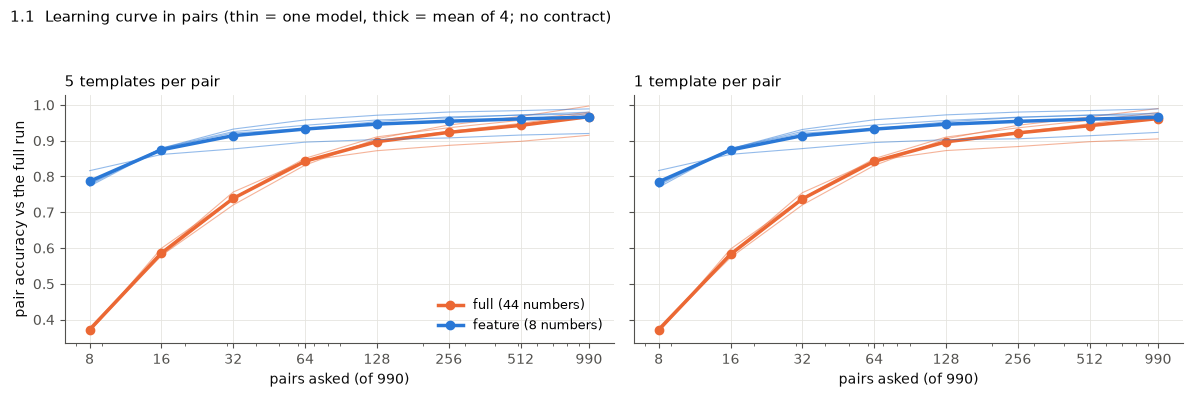

k                      8      16     32     64     128    256    512    990
tmpl        kind                                                           
1 template  feature  0.785  0.874  0.914  0.932  0.946  0.954  0.960  0.965
            full     0.371  0.583  0.737  0.842  0.897  0.922  0.942  0.962
5 templates feature  0.786  0.875  0.914  0.933  0.946  0.954  0.961  0.966
            full     0.371  0.586  0.739  0.843  0.897  0.923  0.943  0.967
full reaches 98% of its own 990-pair accuracy at k = 990
feature reaches 98% of its own 990-pair accuracy at k = 256


In [3]:
DESIGN_F = np.zeros((N, 8)); col = 0
for f in FEATS:                                    # effects coding of each laptop (8 columns)
    L = LEVELS[f]
    for k in range(len(L) - 1):
        for j, lap in enumerate(LAPTOPS):
            v = lap[FEATS.index(f)]
            DESIGN_F[j, col] = 1.0 if v == L[k] else (-1.0 if v == L[-1] else 0.0)
        col += 1
PAIRS = np.array(list(zip(*IU)))

def fit_sample(Dk, idx, kind):
    i, j = PAIRS[idx, 0], PAIRS[idx, 1]; y = Dk[i, j]
    if kind == "full":
        X = np.zeros((len(idx), N)); X[np.arange(len(idx)), i] = 1; X[np.arange(len(idx)), j] = -1
        return np.linalg.lstsq(X, y, rcond=None)[0]
    X = DESIGN_F[i] - DESIGN_F[j]
    return DESIGN_F @ np.linalg.lstsq(X, y, rcond=None)[0]

KS = [8, 16, 32, 64, 128, 256, 512, 990]
MS = ["qwen-32B", "qwen-72B", "gemma-27B", "olmo-32B"]
rng = np.random.default_rng(0); rows = []
for m in MS:
    r = R[(m, "none")]
    for k in KS:
        for rep in range(30 if k < 990 else 1):
            idx = rng.choice(len(PAIRS), k, replace=False)
            for tmpl, Dk in [("5 templates", r.D), ("1 template", r.Dt[rng.integers(5)])]:
                for kind in ["full", "feature"]:
                    u = fit_sample(Dk, idx, kind)
                    rows.append(dict(model=m, k=k, tmpl=tmpl, kind=kind, acc=pair_accuracy(u, r.D), rho=spearmanr(u, r.u)[0]))
PS = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tmpl in zip(axes, ["5 templates", "1 template"]):
    for kind, col in [("full", ORANGE), ("feature", BLUE)]:
        s = PS[(PS.tmpl == tmpl) & (PS.kind == kind)].groupby(["model", "k"]).acc.mean().unstack(0)
        for m in MS: ax.plot(s.index, s[m], color=col, lw=0.8, alpha=0.5)
        ax.plot(s.index, s.mean(axis=1), color=col, lw=2.5, marker="o", label=f"{kind} ({'44' if kind == 'full' else '8'} numbers)")
    ax.set_xscale("log"); ax.set_xticks(KS, KS); ax.set_xlabel("pairs asked (of 990)"); ax.grid(color=GRID, lw=0.6)
    ax.set_title(f"{tmpl} per pair", loc="left")
axes[0].set_ylabel("pair accuracy vs the full run"); axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("1.1  Learning curve in pairs (thin = one model, thick = mean of 4; no contract)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIG}/06_1_pairs.png", dpi=150); plt.show()
T1 = PS.groupby(["tmpl", "kind", "k"]).acc.mean().unstack("k").round(3)
print(T1.to_string())
ceil = PS[(PS.k == 990) & (PS.tmpl == "5 templates")].groupby("kind").acc.mean()
for kind in ["full", "feature"]:
    s = PS[(PS.tmpl == "5 templates") & (PS.kind == kind)].groupby("k").acc.mean()
    print(kind, "reaches 98% of its own 990-pair accuracy at k =", s[s >= 0.98 * ceil[kind]].index.min())

- **The feature model needs far fewer pairs.** With 32 random pairs it already gets 0.91 pair accuracy, with 128 pairs
  0.95; it reaches 98% of its full-data accuracy (0.966) at **256 pairs** — a quarter of the design.
- **The full parametrization needs all of them**: 0.74 at 32 pairs, 0.90 at 128, 0.967 only at 990. With 44 free
  numbers it cannot borrow strength across laptops.
- **One template is as good as five** (the two panels are the same to 3 decimals). Together: one template and 256
  pairs × 2 orders = **512 queries instead of 9,900**, about 5% of a run, for 98% of the accuracy — for laptops, where
  the features explain the taste. (For books they do not, and this saving would not hold.)

## 2. Runs: how many contracts must we run?

qwen-32B has 18 contract runs (plus no contract); qwen-72B has 12. Suppose we could afford only *K* of them. Score =
mean pair accuracy over **all** of that model's contracts:
- a contract we ran is known exactly (its own weights, the oracle) — in both approaches;
- a contract we did **not** run must be guessed:
  - **independent** (one fit per contract, no model across contracts): nothing to go on → "no change";
  - **GRUM**: shrunk sum of the singles we ran if they cover it, else the structured GRUM (σ, ρ, κ from the singles
    we ran; a feature with no single stays as it was). λ is fitted on the **other** models' compound runs.

Two orders of running: **random** (mean of 60 orders), and **GRUM's plan** — first one single per feature, then the
remaining singles, then compounds.

qwen-32B lambda from the other models: 0.681 0.857 | planned order: ['4GB', '13in', 'Dell', '16in', '16GB', 'Apple', '14in', '8GB', '14in + 4GB', 'Dell + 14in', 'Dell + 8GB', 'Dell + 14in + 8GB', 'Apple + 14in', 'Apple + 8GB', 'Apple + 14in + 8GB', 'Dell + 4GB', 'Dell + 14in + 4GB', '14in + 8GB']


qwen-72B lambda from the other models: 0.691 0.847 | planned order: ['4GB', '13in', 'Dell', '16in', '16GB', '14in', '8GB', '14in + 4GB', 'Dell + 8GB', 'Dell + 14in', 'Dell + 14in + 8GB', '14in + 8GB']


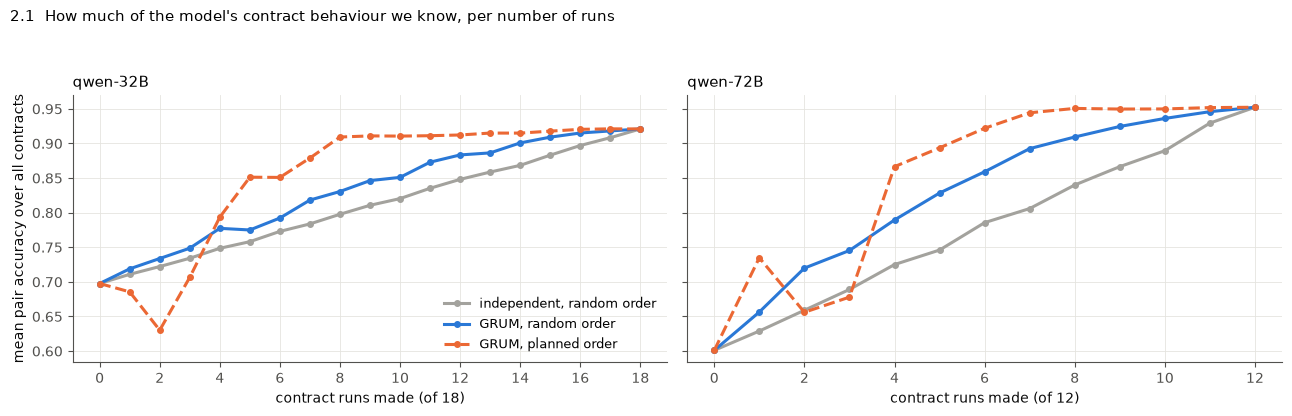

how          GRUM, planned order  GRUM, random order  independent, random order
model    K                                                                     
qwen-32B 0                 0.698               0.698                      0.698
         1                 0.686               0.719                      0.711
         2                 0.630               0.734                      0.722
         3                 0.707               0.749                      0.734
         4                 0.794               0.777                      0.749
         5                 0.851               0.775                      0.758
         6                 0.851               0.792                      0.773
         7                 0.879               0.818                      0.784
         8                 0.909               0.831                      0.798
         9                 0.911               0.846                      0.811
         10                0.911        

In [4]:
COMP_ALL = [(m, c) for (m, c) in R if len(parse(c)) >= 2 and m != "qwen-0.5B"]
def singles_of(m, ran):
    return {(f, l): R[(m, c)].w for c in ran for f, l in parse(c).items() if len(parse(c)) == 1}

def lam_other(m, rule):
    runs = [(mm, c) for mm, c in COMP_ALL if mm != m]
    S = {mm: {(f, l): R[(mm, f"{f}={l}")].w for (x, cc) in R if x == mm for f, l in parse(cc).items() if len(parse(cc)) == 1} for mm, _ in runs}
    Pm = {mm: fit_struct(R[(mm, "none")].w, [(f, l, w) for (f, l), w in S[mm].items()]) for mm in S}
    def err(lam):
        e = 0.0
        for mm, c in runs:
            a, con = R[(mm, "none")].w, parse(c)
            if rule == "sum" and not all(k in S[mm] for k in con.items()): continue
            wp = predict_sum(a, S[mm], con, lam) if rule == "sum" else predict_struct(a, Pm[mm], con, lam)
            e += ((wp - R[(mm, c)].w) ** 2).sum()
        return e
    return minimize_scalar(err, bounds=(0.2, 1.5), method="bounded").x

def guess(m, c, ran, lam_s, lam_t):
    a, con = R[(m, "none")].w, parse(c); S = singles_of(m, ran)
    if all(k in S for k in con.items()):
        return predict_sum(a, S, con, lam_s)
    P = fit_struct(a, [(f, l, w) for (f, l), w in S.items()]) if S else {"sigma": {}, "rho": {}, "kappa": {}}
    for f in FEATS:                                   # features never asked: leave them alone
        P["sigma"].setdefault(f, 0.0); P["rho"].setdefault(f, 0.0)
        for g in FEATS:
            if g != f: P["kappa"].setdefault((f, g), 0.0)
    return predict_struct(a, P, con, lam_t)

def score(m, ran, lam_s, lam_t, grum):
    out = []
    for c in CONS_M[m]:
        if c in ran: w = R[(m, c)].w
        elif grum: w = guess(m, c, ran, lam_s, lam_t)
        else: w = R[(m, "none")].w
        out.append(pair_accuracy(additive_utility(w), R[(m, c)].D))
    return np.mean(out)

CONS_M = {m: [c for (mm, c) in R if mm == m and c != "none"] for m in ["qwen-32B", "qwen-72B"]}
rng = np.random.default_rng(1); rows = []
for m in CONS_M:
    lam_s, lam_t = lam_other(m, "sum"), lam_other(m, "struct")
    cons = CONS_M[m]; n = len(cons)
    sing = [c for c in cons if len(parse(c)) == 1]; comp = [c for c in cons if len(parse(c)) > 1]
    first = []
    for f in ["ram", "screen", "brand"]:              # one single per feature: the hardest level we have
        pref = {"ram": "ram=4GB", "screen": "screen=13-inch", "brand": "brand=Dell"}[f]
        if pref in sing: first.append(pref)
    plan = first + [c for c in sing if c not in first] + comp
    for K in range(n + 1):
        rows.append(dict(model=m, K=K, how="GRUM, planned order", acc=score(m, plan[:K], lam_s, lam_t, True)))
        accs_g, accs_i = [], []
        for rep in range(60):
            order = list(rng.permutation(cons)); ran = order[:K]
            accs_g.append(score(m, ran, lam_s, lam_t, True)); accs_i.append(score(m, ran, lam_s, lam_t, False))
        rows.append(dict(model=m, K=K, how="GRUM, random order", acc=np.mean(accs_g)))
        rows.append(dict(model=m, K=K, how="independent, random order", acc=np.mean(accs_i)))
    print(m, "lambda from the other models:", round(lam_s, 3), round(lam_t, 3), "| planned order:", [short(c) for c in plan])
RU = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, m in zip(axes, CONS_M):
    for how, col, ls in [("independent, random order", GRAY, "-"), ("GRUM, random order", BLUE, "-"), ("GRUM, planned order", ORANGE, "--")]:
        s = RU[(RU.model == m) & (RU.how == how)]
        ax.plot(s.K, s.acc, color=col, lw=2.2, ls=ls, marker="o", ms=4, label=how)
    ax.set_xlabel(f"contract runs made (of {len(CONS_M[m])})"); ax.set_title(m, loc="left"); ax.grid(color=GRID, lw=0.6)
    ax.set_xticks(range(0, len(CONS_M[m]) + 1, 2))
axes[0].set_ylabel("mean pair accuracy over all contracts"); axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.suptitle("2.1  How much of the model's contract behaviour we know, per number of runs", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.93)); fig.savefig(f"{FIG}/06_2_runs.png", dpi=150); plt.show()
print(RU.pivot_table(index=["model", "K"], columns="how", values="acc").round(3).to_string())

- **GRUM learns the contract behaviour from far fewer runs.** qwen-32B: with 5 runs in GRUM's planned order (`4GB`,
  `13in`, `Dell`, `16in`, `16GB`) the mean pair accuracy over all 18 contracts is **0.85**, against 0.76 for one fit per
  contract; all 18 runs give 0.92. qwen-72B: 6 runs give **0.92** (all 12: 0.95), against 0.79.
- **The planned order (singles first) beats a random order** from the 4th run on: the singles carry B, the compounds are
  predictable (notebook 04).
- **The first two runs are the weak spot**: the plan starts with `4GB` and `13in`, the two least transferable levels
  (notebook 02), and accuracy even **drops** below "no change" (qwen-32B 0.70 → 0.63 after 2 runs). Starting with a middle
  level (`8GB`, `14in`) would likely be better.
- Caveat: two models, and the "truth" is the same runs the oracle uses — this measures how many runs we can skip,
  not new data.

## 3. How many numbers does each approach need?

For the laptops, a contract names each feature or not: 6 × 4 × 4 = **96 contracts** (formalization §8). A model of all
of them needs:

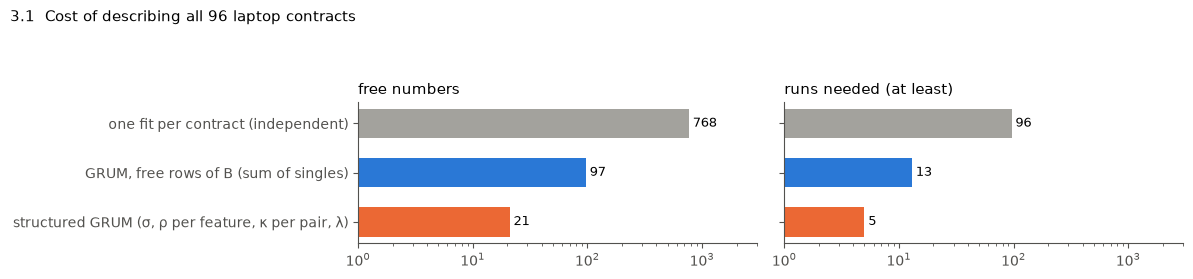

In [5]:
PAR = {"one fit per contract (independent)": 8 * 96, "GRUM, free rows of B (sum of singles)": 8 + 8 * 11 + 1,
       "structured GRUM (σ, ρ per feature, κ per pair, λ)": 8 + 3 + 3 + 6 + 1}
RUNS = {"one fit per contract (independent)": 96, "GRUM, free rows of B (sum of singles)": 1 + 11 + 1,
        "structured GRUM (σ, ρ per feature, κ per pair, λ)": 1 + 3 + 1}
fig, axes = plt.subplots(1, 2, figsize=(12, 2.8), sharey=True)
y = np.arange(3)
for ax, D_, lab in [(axes[0], PAR, "free numbers"), (axes[1], RUNS, "runs needed (at least)")]:
    ax.barh(y, list(D_.values()), color=[GRAY, BLUE, ORANGE], height=0.6)
    for yi, v in zip(y, D_.values()): ax.text(v * 1.08, yi, str(v), va="center", fontsize=9)
    ax.set_xscale("log"); ax.set_title(lab, loc="left"); ax.set_xlim(1, 3000)
axes[0].set_yticks(y, list(PAR)); axes[0].invert_yaxis()
fig.suptitle("3.1  Cost of describing all 96 laptop contracts", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.88)); fig.savefig(f"{FIG}/06_3_params.png", dpi=150); plt.show()

- **Describing all 96 laptop contracts**: one fit per contract needs 768 numbers and 96 runs; the GRUM with free rows
  of B needs 97 numbers and 13 runs; the structured GRUM needs **21 numbers and 5 runs** (no contract, one single per
  feature, one compound).
- The structured cost grows with the number of **features** (κ per pair of features), not with the number of levels.
  Adding a fourth feature (price, 4 levels) takes the contract space from 96 to 480, the structured GRUM from 21 to
  about 32 numbers.

## Summary

| budget | GRUM / feature model | without it |
|---|---|---|
| pairs per run (98% of full accuracy) | **256 pairs, 1 template** (≈ 5% of a run) | full item model: all 990 × 5 |
| runs for all contracts (qwen-32B) | **5 runs → 0.85**, 8 runs → 0.91 (all 18: 0.92) | 5 runs → 0.76 |
| numbers for all 96 contracts | **21** (structured) / 97 (free B) | 768 |

This is the measurement Nir asked for ("reduces num params — measure how this helps"): on laptops the GRUM about halves
the number of runs needed for the same accuracy (qwen-32B: 8 vs 17 runs for 0.91; qwen-72B: 6 vs 11 for 0.92), and the
feature model cuts the queries per run by about 20×, for a small loss of accuracy.